<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/02_type_classification_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


Исходный файл: /content/drive/MyDrive/datasets/pokemon_complete.csv
Все строки CSV: 1350
Основные записи: 1025
Количество типов: 18

Описание признаков:
            hp   attack  defense  sp_attack  sp_defense    speed  height_m  weight_kg
count  1025.00  1025.00  1025.00    1025.00     1025.00  1025.00   1025.00    1025.00
mean     70.18    77.52    72.51      70.08       70.21    67.19      1.21      66.99
std      26.63    29.78    29.29      29.66       26.64    28.72      1.25     121.27
min       1.00     5.00     5.00      10.00       20.00     5.00      0.10       0.10
25%      50.00    55.00    50.00      47.00       50.00    45.00      0.50       8.50
50%      68.00    75.00    70.00      65.00       67.00    65.00      1.00      28.00
75%      85.00   100.00    90.00      90.00       86.00    88.00      1.50      70.00
max     255.00   181.00   230.00     173.00      230.00   200.00     20.00     999.90

Количество покемонов каждого типа:
type_1
Water       134
Normal      11

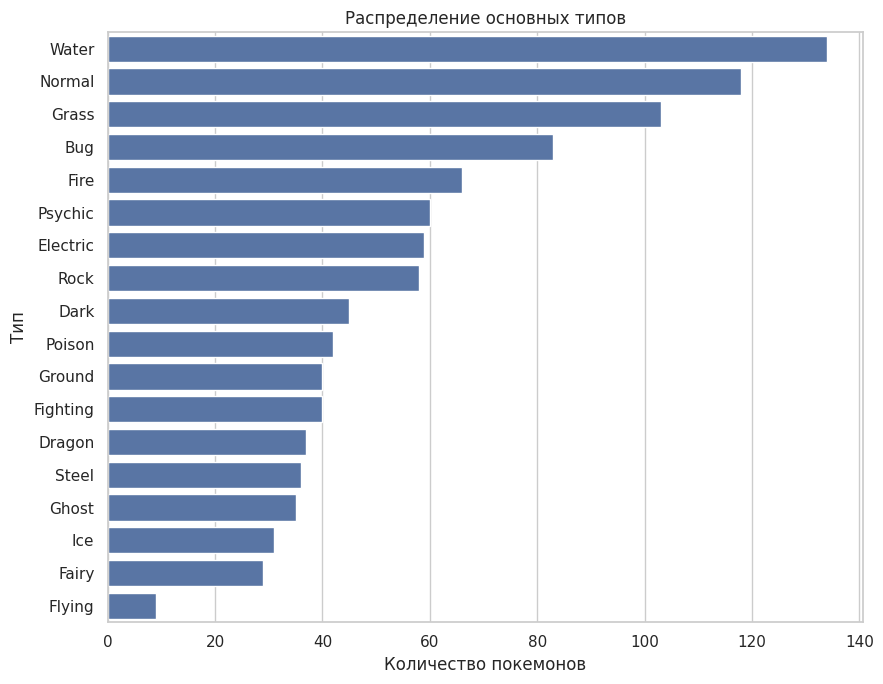

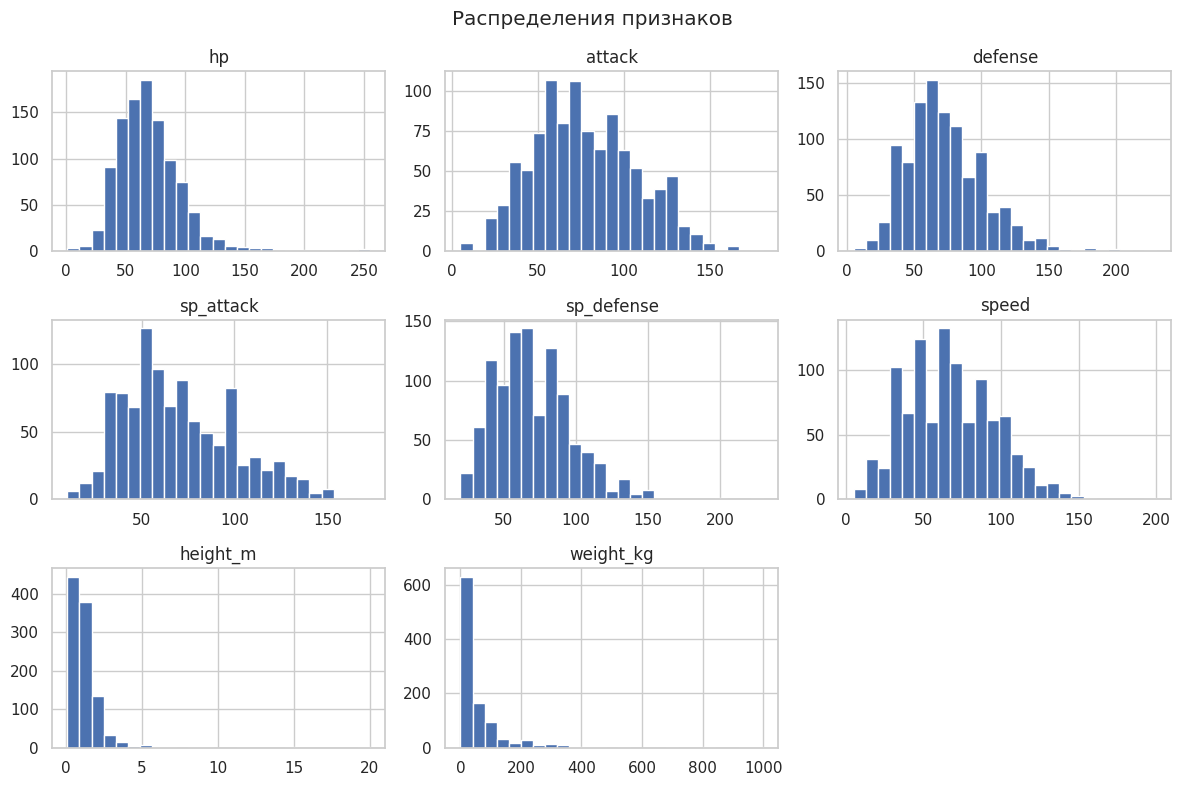

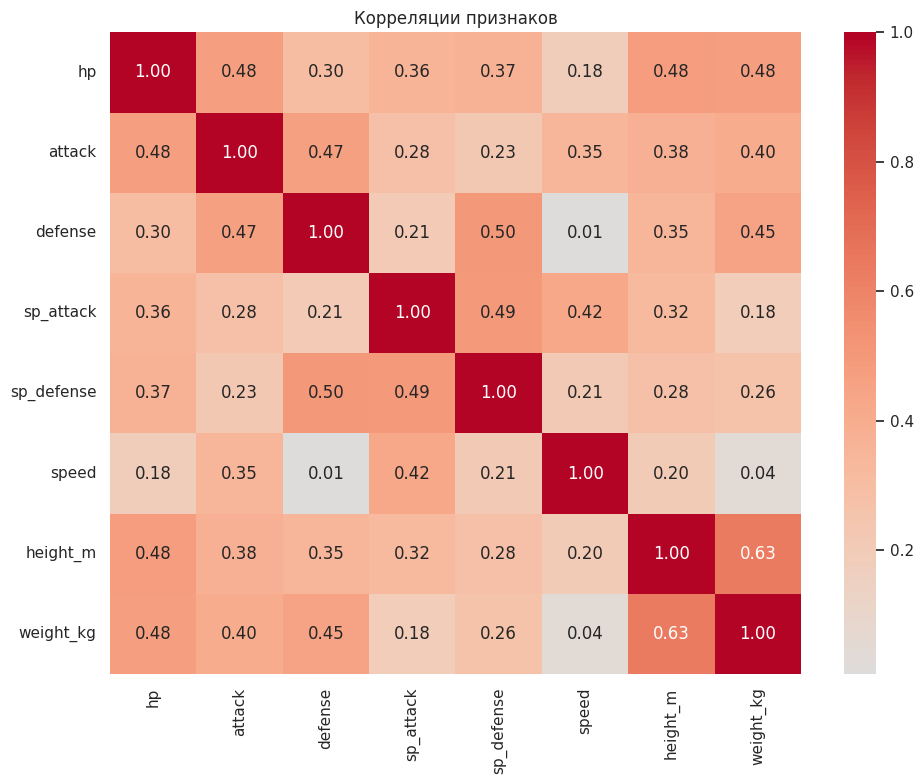


Размеры выборок:
     split  rows  row_share  chains
     train   662      0.646     345
validation   160      0.156      87
      test   203      0.198     109

Представленность типов — строки:
          train  validation  test
type_1                           
Bug          62           7    14
Dark         24          13     8
Dragon       24           6     7
Electric     37           5    17
Fairy         8           8    13
Fighting     24           7     9
Fire         37          23     6
Flying        8           1     0
Ghost        24           1    10
Grass        74          13    16
Ground       17          11    12
Ice          19           6     6
Normal       82          17    19
Poison       28           5     9
Psychic      46           6     8
Rock         32           5    21
Steel        27           6     3
Water        89          20    25

Представленность типов — независимые цепочки:
          train  validation  test
type_1                           
Bug      

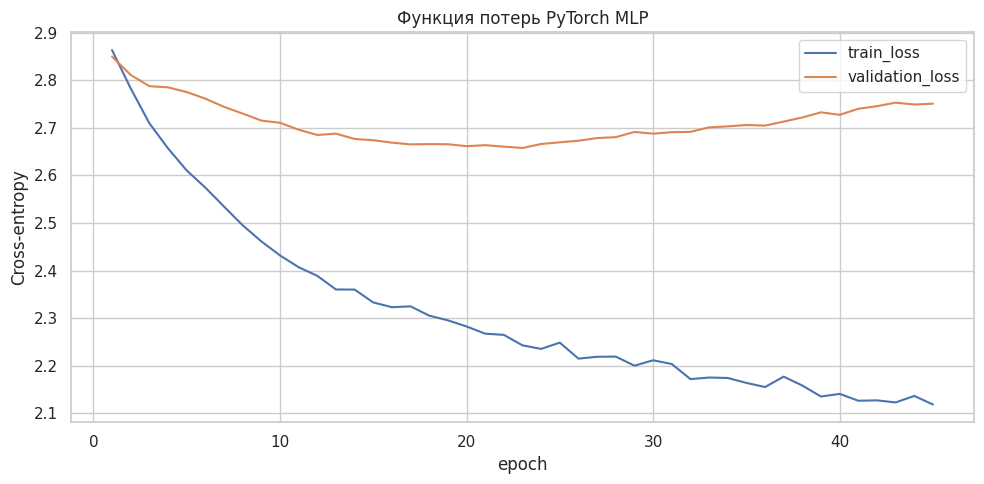

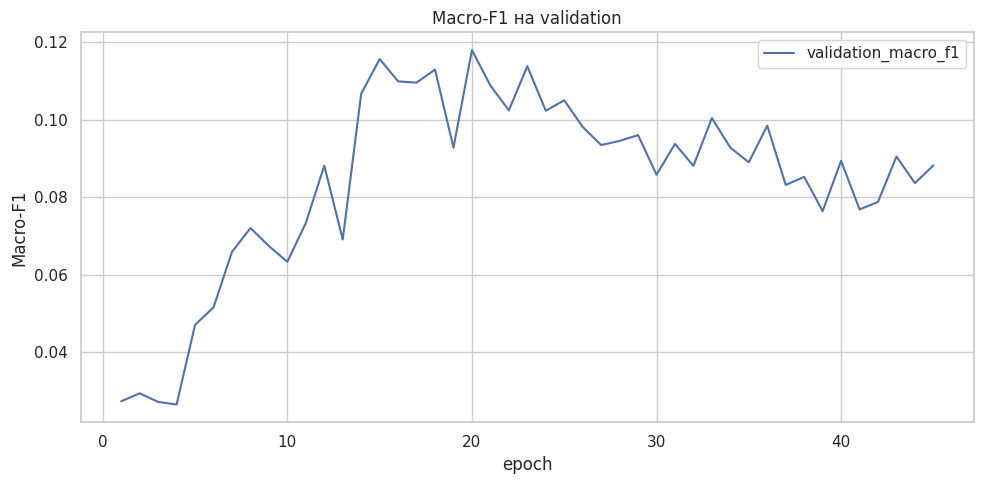


Качество на train и validation:
     split       model  accuracy  balanced_accuracy  macro_f1  weighted_f1
     train       Dummy    0.1344             0.0556    0.0132       0.0319
     train     SVM RBF    0.5423             0.6574    0.5734       0.5254
     train PyTorch MLP    0.2779             0.1971    0.1803       0.2343
validation       Dummy    0.1250             0.0556    0.0123       0.0278
validation     SVM RBF    0.2000             0.1878    0.1590       0.1866
validation PyTorch MLP    0.1812             0.1574    0.1180       0.1284

Рекомендуемая модель по validation: SVM RBF

Итоговые метрики на test:
      model  accuracy  balanced_accuracy  macro_f1  weighted_f1
PyTorch MLP    0.2266             0.2050    0.1415       0.1737
    SVM RBF    0.1527             0.1902    0.1201       0.1334
      Dummy    0.1232             0.0588    0.0122       0.0270

Dummy
          precision  recall  f1-score  support
Bug           0.000     0.0     0.000     14.0
Dark         

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


          precision  recall  f1-score  support
Bug           0.148   0.286     0.195     14.0
Dark          0.000   0.000     0.000      8.0
Dragon        1.000   0.143     0.250      7.0
Electric      0.077   0.059     0.067     17.0
Fairy         0.000   0.000     0.000     13.0
Fighting      0.400   0.444     0.421      9.0
Fire          0.000   0.000     0.000      6.0
Flying        0.000   0.000     0.000      0.0
Ghost         0.000   0.000     0.000     10.0
Grass         0.214   0.562     0.310     16.0
Ground        0.667   0.167     0.267     12.0
Ice           0.000   0.000     0.000      6.0
Normal        0.286   0.632     0.393     19.0
Poison        0.000   0.000     0.000      9.0
Psychic       0.067   0.125     0.087      8.0
Rock          0.000   0.000     0.000     21.0
Steel         0.118   0.667     0.200      3.0
Water         0.323   0.400     0.357     25.0

Ошибок: 157 из 203
 pokedex_number      name  evolution_chain_id   type_1  hp  attack  defense  sp_attack 

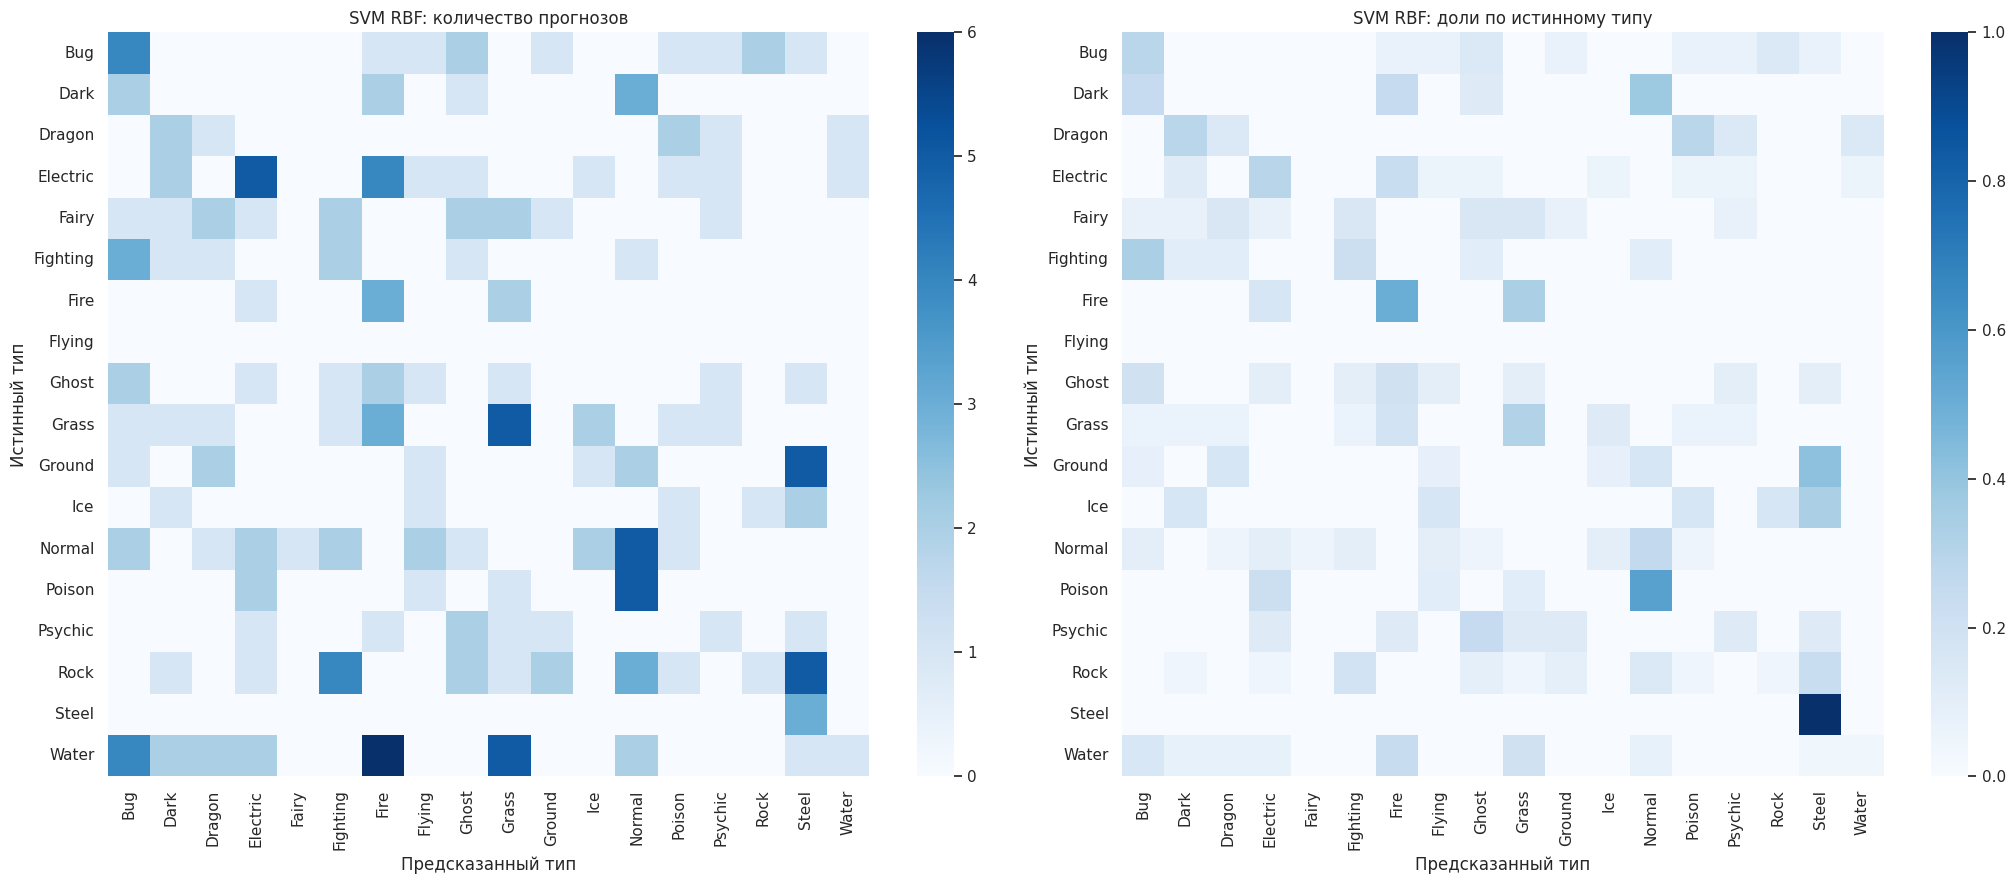


Результаты сохранены в: /content/drive/MyDrive/classification_results_1


In [3]:
# 02_type_classification.py
# Классификация основного типа покемона:
# DummyClassifier, SVM RBF и PyTorch MLP.

from pathlib import Path
import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)


# ============================================================
# 1. Настройки
# ============================================================

SEED = 42

FEATURES = [
    "hp",
    "attack",
    "defense",
    "sp_attack",
    "sp_defense",
    "speed",
    "height_m",
    "weight_kg",
]

TARGET = "type_1"
GROUP = "evolution_chain_id"

BASE_DIR = Path("/content/drive/MyDrive")

PATH = BASE_DIR / "datasets" / "pokemon_complete.csv"

OUTPUT_DIR = BASE_DIR / "classification_results_1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not PATH.is_file():
    raise FileNotFoundError(f"CSV-файл не найден: {PATH}")

MAX_EPOCHS = 300
PATIENCE = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.001

# Для небольшого датасета достаточно CPU.
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")


def show_and_save(filename):
    """Сохраняет текущий график, затем показывает его."""
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# ============================================================
# 2. Загрузка и проверка данных
# ============================================================

if not PATH.is_file():
    raise FileNotFoundError(f"CSV-файл не найден: {PATH}")

raw = pd.read_csv(PATH, encoding="utf-8-sig")

required_columns = [
    "pokedex_number",
    "name",
    TARGET,
    GROUP,
    *FEATURES,
]

missing_columns = set(required_columns) - set(raw.columns)

if missing_columns:
    raise ValueError(
        f"В CSV отсутствуют столбцы: {sorted(missing_columns)}"
    )

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"],
    errors="raise",
)

# Для данного CSV основные записи имеют ID от 1 до 1025.
# Альтернативные формы пока исключаем, чтобы уменьшить
# влияние близких и повторяющихся записей.
df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy()

df = df.reset_index(drop=True)

if df.empty:
    raise ValueError("После отбора основных записей выборка пуста")

if not df["pokedex_number"].is_unique:
    raise ValueError("Обнаружены повторяющиеся pokedex_number")

if df[[TARGET, GROUP]].isna().any().any():
    raise ValueError("Обнаружены пропуски в target или ID цепочки")

df[TARGET] = df[TARGET].astype(str).str.strip()

if df[TARGET].eq("").any():
    raise ValueError("Обнаружены пустые названия типов")

df[FEATURES] = df[FEATURES].apply(
    pd.to_numeric,
    errors="raise",
)

if df[FEATURES].isna().any().any():
    raise ValueError(
        "В признаках обнаружены пропуски:\n"
        + df[FEATURES].isna().sum().to_string()
    )

if not np.isfinite(
    df[FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Обнаружены бесконечные значения признаков")

if (df[FEATURES] < 0).any().any():
    raise ValueError("Обнаружены отрицательные характеристики")

print(f"Исходный файл: {PATH}")
print(f"Все строки CSV: {len(raw)}")
print(f"Основные записи: {len(df)}")
print(f"Количество типов: {df[TARGET].nunique()}")

print("\nОписание признаков:")
print(df[FEATURES].describe().round(2).to_string())

print("\nКоличество покемонов каждого типа:")
print(df[TARGET].value_counts().to_string())


# ============================================================
# 3. Первичный анализ
# ============================================================

plt.figure(figsize=(9, 7))
sns.countplot(
    data=df,
    y=TARGET,
    order=df[TARGET].value_counts().index,
)
plt.title("Распределение основных типов")
plt.xlabel("Количество покемонов")
plt.ylabel("Тип")
show_and_save("01_type_distribution.png")

df[FEATURES].hist(figsize=(12, 8), bins=25)
plt.suptitle("Распределения признаков")
show_and_save("02_feature_distributions.png")

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[FEATURES].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Корреляции признаков")
show_and_save("03_correlations.png")


# ============================================================
# 4. Разбиение по эволюционным цепочкам
# ============================================================

# Один фиксированный групповой holdout.
# Доли относятся к группам, поэтому доли строк приблизительные.
outer_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED,
)

trainval_idx, test_idx = next(
    outer_split.split(df, groups=df[GROUP])
)

trainval = df.iloc[trainval_idx].copy()
test = df.iloc[test_idx].copy()

inner_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED,
)

train_idx, val_idx = next(
    inner_split.split(trainval, groups=trainval[GROUP])
)

train = trainval.iloc[train_idx].copy()
val = trainval.iloc[val_idx].copy()

parts = {
    "train": train,
    "validation": val,
    "test": test,
}

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "row_share": len(part) / len(df),
        "chains": part[GROUP].nunique(),
    }
    for name, part in parts.items()
])

print("\nРазмеры выборок:")
print(summary.round(3).to_string(index=False))

# Проверяем отсутствие пересечений групп и строк.
for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if set(parts[first][GROUP]) & set(parts[second][GROUP]):
        raise ValueError(
            f"Пересечение цепочек: {first} / {second}"
        )

all_ids = pd.concat([
    part["pokedex_number"] for part in parts.values()
])

if (
    not all_ids.is_unique
    or len(all_ids) != len(df)
    or set(all_ids) != set(df["pokedex_number"])
):
    raise ValueError("Некорректное распределение строк по выборкам")

types = sorted(df[TARGET].unique())

counts = pd.DataFrame({
    name: part[TARGET].value_counts()
    for name, part in parts.items()
}).reindex(types).fillna(0).astype(int)

chain_counts = pd.DataFrame({
    name: part.groupby(TARGET)[GROUP].nunique()
    for name, part in parts.items()
}).reindex(types).fillna(0).astype(int)

print("\nПредставленность типов — строки:")
print(counts.to_string())

print("\nПредставленность типов — независимые цепочки:")
print(chain_counts.to_string())

# Не удаляем неизвестные классы молча.
unseen = (
    set(val[TARGET]) | set(test[TARGET])
) - set(train[TARGET])

if unseen:
    raise ValueError(
        f"Типы {sorted(unseen)} отсутствуют в train. "
        "Нужно пересмотреть групповой протокол разбиения "
        "по представленности классов, а не по качеству test."
    )

for split_name in ["validation", "test"]:
    absent = counts.index[counts[split_name] == 0].tolist()
    few = counts.index[counts[split_name].between(1, 4)].tolist()

    if absent:
        print(
            f"\nПредупреждение: в {split_name} "
            f"отсутствуют типы {absent}"
        )

    if few:
        print(
            f"Предупреждение: в {split_name} "
            f"только 1–4 объекта типов {few}"
        )

# Фиксированный набор классов для macro-F1.
CLASSES = np.array(sorted(train[TARGET].unique()))

split_table = pd.concat([
    part[
        ["pokedex_number", "name", TARGET, GROUP]
    ].assign(split=name)
    for name, part in parts.items()
])

split_table.to_csv(
    OUTPUT_DIR / "split.csv",
    index=False,
    encoding="utf-8-sig",
)

counts.to_csv(
    OUTPUT_DIR / "type_counts.csv",
    encoding="utf-8-sig",
)

summary.to_csv(
    OUTPUT_DIR / "split_sizes.csv",
    index=False,
)


# ============================================================
# 5. Baseline
# ============================================================

# Всегда предсказывает самый частый тип из train.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train[FEATURES], train[TARGET])


# ============================================================
# 6. SVM: подбор параметров по validation
# ============================================================

svm_models = {}
svm_rows = []

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1]:
        for class_weight in [None, "balanced"]:
            svm_candidate = make_pipeline(
                StandardScaler(),
                SVC(
                    kernel="rbf",
                    C=C,
                    gamma=gamma,
                    class_weight=class_weight,
                ),
            )

            # StandardScaler обучается только на train.
            svm_candidate.fit(
                train[FEATURES],
                train[TARGET],
            )

            prediction = svm_candidate.predict(val[FEATURES])

            score = f1_score(
                val[TARGET],
                prediction,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )

            key = (
                float(C),
                str(gamma),
                str(class_weight),
            )
            svm_models[key] = svm_candidate

            svm_rows.append({
                "C": C,
                "gamma": str(gamma),
                "class_weight": str(class_weight),
                "validation_macro_f1": score,
            })

svm_results = pd.DataFrame(svm_rows).sort_values(
    "validation_macro_f1",
    ascending=False,
    kind="stable",
)

print("\nПодбор SVM:")
print(svm_results.round(4).to_string(index=False))

best_svm_row = svm_results.iloc[0]

best_key = (
    float(best_svm_row["C"]),
    best_svm_row["gamma"],
    best_svm_row["class_weight"],
)

svm = svm_models[best_key]

print("\nВыбранные параметры SVM:")
print(best_svm_row.to_string())

svm_results.to_csv(
    OUTPUT_DIR / "svm_validation_search.csv",
    index=False,
)


# ============================================================
# 7. Подготовка данных PyTorch
# ============================================================

nn_scaler = StandardScaler()

X_train = nn_scaler.fit_transform(
    train[FEATURES]
).astype("float32")

X_val = nn_scaler.transform(
    val[FEATURES]
).astype("float32")

encoder = LabelEncoder()
y_train = encoder.fit_transform(train[TARGET])
y_val = encoder.transform(val[TARGET])

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.tensor(y_train, dtype=torch.long),
)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
)

X_val_tensor = torch.from_numpy(X_val).to(DEVICE)
y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long,
    device=DEVICE,
)


# ============================================================
# 8. Нейросеть
# ============================================================

mlp = nn.Sequential(
    nn.Linear(len(FEATURES), 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, len(encoder.classes_)),
).to(DEVICE)

# Выход — logits. Softmax перед CrossEntropyLoss не нужен.
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=LEARNING_RATE,
)

history_rows = []
best_val_score = -1.0
best_state = None
best_epoch = 0
waiting = 0


# ============================================================
# 9. Обучение и ранняя остановка
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        logits = mlp(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    mlp.eval()

    with torch.no_grad():
        val_logits = mlp(X_val_tensor)
        val_loss = criterion(
            val_logits,
            y_val_tensor,
        ).item()

        val_ids = val_logits.argmax(dim=1).cpu().numpy()

    val_score = f1_score(
        y_val,
        val_ids,
        labels=np.arange(len(encoder.classes_)),
        average="macro",
        zero_division=0,
    )

    history_rows.append({
        "epoch": epoch,
        "train_loss": total_loss / len(train_dataset),
        "validation_loss": val_loss,
        "validation_macro_f1": val_score,
    })

    if val_score > best_val_score:
        best_val_score = val_score
        best_state = copy.deepcopy(mlp.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train loss={total_loss / len(train_dataset):.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val macro-F1={val_score:.4f}"
        )

    if waiting >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}")
        break

mlp.load_state_dict(best_state)
mlp.eval()

print(
    f"\nЛучшая эпоха MLP: {best_epoch}; "
    f"validation macro-F1={best_val_score:.4f}"
)

history = pd.DataFrame(history_rows)

history.to_csv(
    OUTPUT_DIR / "mlp_history.csv",
    index=False,
)

history.plot(
    x="epoch",
    y=["train_loss", "validation_loss"],
    figsize=(10, 5),
)
plt.title("Функция потерь PyTorch MLP")
plt.ylabel("Cross-entropy")
show_and_save("04_mlp_loss.png")

history.plot(
    x="epoch",
    y="validation_macro_f1",
    figsize=(10, 5),
)
plt.title("Macro-F1 на validation")
plt.ylabel("Macro-F1")
show_and_save("05_mlp_validation_f1.png")


# ============================================================
# 10. Общие функции прогнозирования и оценки
# ============================================================

def predict_mlp(part):
    X = nn_scaler.transform(
        part[FEATURES]
    ).astype("float32")

    mlp.eval()

    with torch.no_grad():
        logits = mlp(torch.from_numpy(X).to(DEVICE))
        predicted_ids = logits.argmax(dim=1).cpu().numpy()

    return encoder.inverse_transform(predicted_ids)


def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
    }


# ============================================================
# 11. Проверка переобучения: train и validation
# ============================================================

diagnostic_rows = []

for split_name, part in {
    "train": train,
    "validation": val,
}.items():
    split_predictions = {
        "Dummy": baseline.predict(part[FEATURES]),
        "SVM RBF": svm.predict(part[FEATURES]),
        "PyTorch MLP": predict_mlp(part),
    }

    for model_name, prediction in split_predictions.items():
        diagnostic_rows.append({
            "split": split_name,
            "model": model_name,
            **calculate_metrics(part[TARGET], prediction),
        })

diagnostics = pd.DataFrame(diagnostic_rows)

print("\nКачество на train и validation:")
print(diagnostics.round(4).to_string(index=False))

diagnostics.to_csv(
    OUTPUT_DIR / "train_validation_metrics.csv",
    index=False,
)

# Выбираем рекомендуемую обучаемую модель по validation.
# Test пока не использован для выбора.
validation_candidates = diagnostics.loc[
    (diagnostics["split"] == "validation")
    & (diagnostics["model"] != "Dummy")
]

recommended_model = validation_candidates.sort_values(
    "macro_f1",
    ascending=False,
    kind="stable",
).iloc[0]["model"]

print(
    "\nРекомендуемая модель по validation:",
    recommended_model,
)


# ============================================================
# 12. Итоговая оценка на test
# ============================================================

# После этого этапа не подбираем параметры по результатам test.
test_predictions = {
    "Dummy": baseline.predict(test[FEATURES]),
    "SVM RBF": svm.predict(test[FEATURES]),
    "PyTorch MLP": predict_mlp(test),
}

test_results = pd.DataFrame([
    {
        "model": model_name,
        **calculate_metrics(test[TARGET], prediction),
    }
    for model_name, prediction in test_predictions.items()
]).sort_values("macro_f1", ascending=False)

print("\nИтоговые метрики на test:")
print(test_results.round(4).to_string(index=False))

test_results.to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False,
)


# ============================================================
# 13. Ошибки каждой модели
# ============================================================

for model_name, prediction in test_predictions.items():
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
    )

    print("\n" + "=" * 60)
    print(model_name)

    report = pd.DataFrame(
        classification_report(
            test[TARGET],
            prediction,
            labels=CLASSES,
            output_dict=True,
            zero_division=0,
        )
    ).T

    print(
        report.loc[
            CLASSES,
            ["precision", "recall", "f1-score", "support"],
        ].round(3).to_string()
    )

    report.to_csv(
        OUTPUT_DIR / f"{safe_name}_report.csv",
        encoding="utf-8-sig",
    )

    prediction_table = test[
        ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
    ].copy()

    prediction_table["prediction"] = prediction
    prediction_table["correct"] = (
        prediction_table[TARGET]
        == prediction_table["prediction"]
    )

    errors = prediction_table.loc[
        ~prediction_table["correct"]
    ]

    print(f"\nОшибок: {len(errors)} из {len(test)}")
    print(errors.head(15).to_string(index=False))

    pairs = (
        errors.groupby([TARGET, "prediction"])
        .size()
        .sort_values(ascending=False)
        .rename("count")
    )

    print("\nСамые частые пары ошибок:")
    print(pairs.head(10).to_string())

    prediction_table.to_csv(
        OUTPUT_DIR / f"{safe_name}_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

    pairs.to_csv(
        OUTPUT_DIR / f"{safe_name}_error_pairs.csv",
        encoding="utf-8-sig",
    )


# ============================================================
# 14. Матрица ошибок рекомендуемой модели
# ============================================================

chosen_prediction = test_predictions[recommended_model]

matrix = confusion_matrix(
    test[TARGET],
    chosen_prediction,
    labels=CLASSES,
)

# Нормирование по истинным классам.
# Строки без тестовых примеров оставляем нулевыми.
row_totals = matrix.sum(axis=1, keepdims=True)

normalized_matrix = np.divide(
    matrix,
    row_totals,
    out=np.zeros_like(matrix, dtype=float),
    where=row_totals != 0,
)

fig, axes = plt.subplots(1, 2, figsize=(21, 9))

sns.heatmap(
    matrix,
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(
    f"{recommended_model}: количество прогнозов"
)

sns.heatmap(
    normalized_matrix,
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues",
    vmin=0,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title(
    f"{recommended_model}: доли по истинному типу"
)

for ax in axes:
    ax.set_xlabel("Предсказанный тип")
    ax.set_ylabel("Истинный тип")
    ax.tick_params(axis="x", labelrotation=90)
    ax.tick_params(axis="y", labelrotation=0)

show_and_save("06_confusion_matrix.png")


# ============================================================
# 15. Сохранение обученных моделей
# ============================================================

# Загружайте joblib и PyTorch-файлы только из доверенных источников.
joblib.dump(
    {
        "baseline": baseline,
        "svm": svm,
        "mlp_scaler": nn_scaler,
        "label_encoder": encoder,
        "features": FEATURES,
        "target": TARGET,
        "recommended_model": recommended_model,
    },
    OUTPUT_DIR / "classification_models.joblib",
)

torch.save(
    {
        "state_dict": mlp.state_dict(),
        "input_dim": len(FEATURES),
        "num_classes": len(encoder.classes_),
        "classes": encoder.classes_.tolist(),
        "features": FEATURES,
        "best_epoch": best_epoch,
        "seed": SEED,
    },
    OUTPUT_DIR / "mlp_checkpoint.pt",
)

print(f"\nРезультаты сохранены в: {OUTPUT_DIR}")